In [11]:
import tensorflow as tf
import pandas as pd
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, RepeatVector, TimeDistributed
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

In [12]:
data = pd.read_csv("energy consumption.csv")
print(data.head())
print(data.shape)

          Timestamp  Electricity_Consumed  Temperature  Humidity  Wind_Speed  \
0  01-01-2024 00:00              0.457786     0.469524  0.396368    0.445441   
1  01-01-2024 00:30              0.351956     0.465545  0.451184    0.458729   
2  01-01-2024 01:00              0.482948     0.285415  0.408289    0.470360   
3  01-01-2024 01:30              0.628838     0.482095  0.512308    0.576241   
4  01-01-2024 02:00              0.335974     0.624741  0.672021    0.373004   

   Avg_Past_Consumption  Anomaly_Label  
0              0.692057              0  
1              0.539874              0  
2              0.614724              0  
3              0.757044              0  
4              0.673981              0  
(5000, 7)


In [13]:
print(data.isnull().sum())

Timestamp               0
Electricity_Consumed    0
Temperature             0
Humidity                0
Wind_Speed              0
Avg_Past_Consumption    0
Anomaly_Label           0
dtype: int64


In [14]:
data['Timestamp'] = pd.to_datetime(data['Timestamp'], format="%d-%m-%Y %H:%M")
data = data.sort_values('Timestamp')

In [15]:
x = data.drop(["Timestamp", "Anomaly_Label"], axis=1).values
y = data["Anomaly_Label"].values

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, shuffle=False
)

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

x_train_normal = x_train[y_train==0]
scaler = StandardScaler()
scaler.fit(x_train_normal)

x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

Training data:  (4000, 5)
Testing data:  (1000, 5)
Training data:  (4000, 5)
Testing data:  (1000, 5)


In [22]:
window_size = 10

def create_windows(x, y):
    x_window = []
    y_window = []
    for i in range(len(x) - window_size + 1):
        x_window.append(x[i:i+window_size])
        y_window.append(np.max(y[i:i+window_size]))
        
    return np.array(x_window), np.array(y_window)

x_train_window, y_train_window = create_windows(x_train, y_train)
x_test_window, y_test_window = create_windows(x_test, y_test)

x_train_window = x_train_window[y_train_window==0]

In [23]:
model = Sequential()

model.add(LSTM(32, activation='relu', input_shape=(window_size, x_train.shape[1])))
model.add(RepeatVector(window_size))
model.add(LSTM(32, activation='relu', return_sequences=True))
model.add(TimeDistributed(Dense(x_train.shape[1])))

model.compile(
    optimizer = tf.keras.optimizers.Adam(),
    loss = 'mse',
    metrics = ['mae']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                        │ (None, 32)                  │           4,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_2 (RepeatVector)       │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_1 (TimeDistributed) │ (None, 10, 5)               │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,349 (52.14 KB)

 Trainable params: 13,349 (52.14 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
history = model.fit(
    x_train_window, x_train_window,
    epochs = 10,
    batch_size = 32,
    validation_split = 0.2
)

Epoch 1/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - loss: 0.8898 - mae: 0.7472 - val_loss: 0.8396 - val_mae: 0.7212
Epoch 2/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.7937 - mae: 0.6976 - val_loss: 0.7954 - val_mae: 0.6960
Epoch 3/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.7548 - mae: 0.6733 - val_loss: 0.7644 - val_mae: 0.6761
Epoch 4/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.7241 - mae: 0.6558 - val_loss: 0.7387 - val_mae: 0.6647
Epoch 5/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.7028 - mae: 0.6447 - val_loss: 0.7208 - val_mae: 0.6551
Epoch 6/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.6884 - mae: 0.6367 - val_loss: 0.7039 - val_mae: 0.6462
Epoch 7/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.6738 - mae: 0.6281 - val_loss: 0.6922 - val_mae: 0.6392
Epoch 8/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.6640 - mae: 0.6225 - val_loss: 0.6831 - val_mae: 0.6336
Epoch 9/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.651

In [37]:
#train
train_predictions = model.predict(x_train_window)
train_errors = np.mean(np.square(x_train_window - train_predictions), axis=(1, 2))

#threshold = np.mean(train_errors) + 3*np.std(train_errors)
threshold = np.percentile(train_errors, 95)
print("Threshold: ", threshold)

89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Threshold:  0.8939261418143704


In [38]:
#test
test_predictions = model.predict(x_test_window)
errors = np.mean(np.square(x_test_window - test_predictions), axis=(1, 2))

y_pred = (errors > threshold).astype(int)

print("Predicted anomalies:")
print(y_pred[:20])

print("Minimum error:", np.min(errors))
print("Maximum error:", np.max(errors))
print("Mean error:", np.mean(errors))

print("Total anomalies: ", np.sum(y_pred))

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Predicted anomalies:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Minimum error: 0.33338517667758133
Maximum error: 1.0522359761690963
Mean error: 0.6501422968991756
Total anomalies:  56


In [39]:
print("Confusion matrix: ", confusion_matrix(y_test_window, y_pred))
print("Classification report: ", classification_report(y_test_window, y_pred, zero_division=0))

Confusion matrix:  [[671  27]
 [264  29]]
Classification report:                precision    recall  f1-score   support

           0       0.72      0.96      0.82       698
           1       0.52      0.10      0.17       293

    accuracy                           0.71       991
   macro avg       0.62      0.53      0.49       991
weighted avg       0.66      0.71      0.63       991



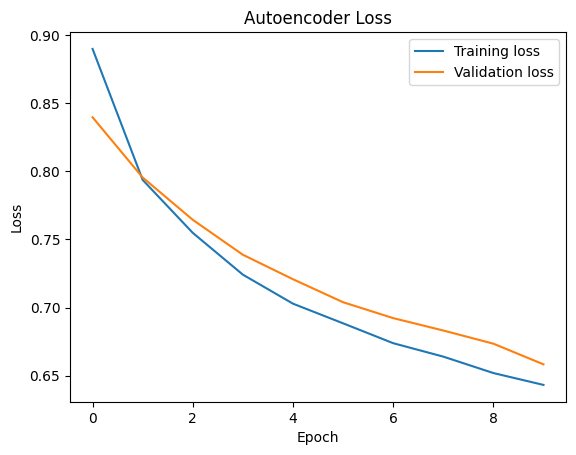

In [40]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label="Training loss")
plt.plot(history.history['val_loss'], label="Validation loss")
plt.title("Autoencoder Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()